# TP Jour 2 — Modèle d'Exécution Spark, Jointures Multi-Datasets & Couche Silver (Delta Lake)

### Objectifs de la séance
1. Observer la **Lazy Evaluation** et distinguer transformations **Narrow** vs **Wide (Shuffle)** sur **Spark Web UI** (`http://localhost:4040`).
2. Profiler la qualité de vos tables **Bronze** (issues d'un ou **plusieurs datasets Kaggle**), nettoyer les anomalies, typer fortement les colonnes et harmoniser les **clés de jointure inter-sources**.
3. Mettre en œuvre une **jointure distribuée multi-datasets maîtrisée** (`BroadcastHashJoin` via `F.broadcast` pour un référentiel/dataset compact, ou `SortMergeJoin` entre deux grandes sources) **en contrôlant la cardinalité (absence d'explosion N-à-M)**.
4. Sauvegarder votre table analytique enrichie dans **`/lakehouse/silver/`** et expérimenter les garanties **ACID de Delta Lake** (`_delta_log`, **Schema Enforcement**, **`MERGE INTO`**, **Time Travel**).

In [12]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from delta.tables import DeltaTable

spark = (
    SparkSession.builder
    .appName("J2_Spark_Delta_Silver")
    .getOrCreate()
)

print("Session Spark active — Spark UI : http://localhost:4040")

Session Spark active — Spark UI : http://localhost:4040


## 1. Chargement de vos tables Bronze (Multi-Datasets / Multi-Tables) & Diagnostic Qualité

### Exercice 1.1 — Charger toutes vos tables Bronze et profiler valeurs manquantes / doublons
1. Chargez dans `bronze_dfs` votre table de faits principale ainsi que la (ou les) table(s) secondaire(s) à joindre depuis `/lakehouse/bronze/<nom_table>`.
2. Comptez le nombre de valeurs `NULL` sur vos colonnes clés (en particulier les **clés de jointure**) ainsi que les doublons éventuels.

In [13]:
from pyspark.sql import functions as F

# 1. Déclarer les 5 tables Bronze de football
BRONZE_TABLES = {
    "main": "/lakehouse/bronze/transfers",
    "players": "/lakehouse/bronze/players",
    "clubs": "/lakehouse/bronze/clubs",
    "leagues": "/lakehouse/bronze/leagues",
    "club_league": "/lakehouse/bronze/club_league"
}

# 2. Charger les tables Delta Lake depuis HDFS
bronze_dfs = {
    alias: spark.read.format("delta").load(path)
    for alias, path in BRONZE_TABLES.items()
}

# 3. Afficher le nombre de lignes et les colonnes
for alias, df in bronze_dfs.items():
    print(
        f"[{alias}] {BRONZE_TABLES[alias]} -> "
        f"{df.count():,} lignes | colonnes : {df.columns[:8]}"
    )

# 4. Sélectionner la table principale : les transferts
df_bronze = bronze_dfs["main"]

# 5. Calculer le nombre de valeurs NULL par colonne
null_report = df_bronze.select([
    F.sum(F.col(f"`{c}`").isNull().cast("int")).alias(c)
    for c in df_bronze.columns
])

# 6. Afficher le diagnostic
null_report.show(truncate=False)

[main] /lakehouse/bronze/transfers -> 3,469,314 lignes | colonnes : ['player_id', 'year', 'left_club_id', 'joined_club_id', 'transfer_fee', 'transfer_type', '_source_file', '_ingested_at']
[players] /lakehouse/bronze/players -> 858,947 lignes | colonnes : ['id', 'url', 'name', 'full_name', 'birth_date', 'death_date', 'height', 'citizenship_1']
[clubs] /lakehouse/bronze/clubs -> 12,963 lignes | colonnes : ['id', 'url', 'club_name', 'id_current_league', 'current_mv', '_source_file', '_ingested_at', '_source_dataset']
[leagues] /lakehouse/bronze/leagues -> 475 lignes | colonnes : ['id', 'url', 'league_name', 'country', 'current_mv', '_source_file', '_ingested_at', '_source_dataset']
[club_league] /lakehouse/bronze/club_league -> 127,980 lignes | colonnes : ['club_id', 'league_id', 'season', 'squad', 'market_value', '_source_file', '_ingested_at', '_source_dataset']


+---------+----+------------+--------------+------------+-------------+------------+------------+---------------+
|player_id|year|left_club_id|joined_club_id|transfer_fee|transfer_type|_source_file|_ingested_at|_source_dataset|
+---------+----+------------+--------------+------------+-------------+------------+------------+---------------+
|0        |0   |0           |0             |0           |0            |0           |0           |0              |
+---------+----+------------+--------------+------------+-------------+------------+------------+---------------+



### 1.2 — EDA du marché des transferts
On mesure d’abord la qualité de `transfers`, puis on explore son activité par année, ses types de transferts et ses indemnités. Les montants absents, nuls, négatifs et positifs sont comptés séparément. Les indicateurs d’indemnité typique portent sur les montants strictement positifs.

In [14]:
from pyspark.sql import functions as F

business_fields = [c for c in bronze_dfs["main"].columns if not c.startswith("_")]
eda_source = bronze_dfs["main"].select(*business_fields)
eda = eda_source.select(
    F.col("year").try_cast("int").alias("year"),
    F.col("transfer_fee").try_cast("double").alias("fee"),
    F.col("player_id").try_cast("bigint").alias("player_id"),
    F.col("left_club_id").try_cast("bigint").alias("left_club_id"),
    F.col("joined_club_id").try_cast("bigint").alias("joined_club_id"),
    F.coalesce(F.nullif(F.trim("transfer_type"), F.lit("")), F.lit("Non renseigné")).alias("type"),
)
eda.printSchema()
finite_fee = F.col("fee").isNotNull() & (F.abs("fee") < float("inf"))
quality_j2 = eda.agg(
    F.count("*").alias("total"),
    F.count_if(F.col("year").isNull()).alias("annee_absente"),
    F.count_if(F.col("player_id").isNull()).alias("joueur_absent"),
    F.count_if(F.col("left_club_id").isNull()).alias("club_depart_absent"),
    F.count_if(F.col("joined_club_id").isNull()).alias("club_arrivee_absent"),
    F.count_if(~finite_fee).alias("indemnite_absente_ou_invalide"),
    F.count_if(finite_fee & (F.col("fee") < 0)).alias("indemnite_negative"),
    F.count_if(F.col("fee") == 0).alias("indemnite_zero"),
    F.count_if(finite_fee & (F.col("fee") > 0)).alias("indemnite_positive"),
)
quality_j2.show(vertical=True)
duplicate_count = quality_j2.first()["total"] - eda_source.dropDuplicates().count()
print(f"Doublons exacts sur les colonnes métier : {duplicate_count:,}")

root
 |-- year: integer (nullable = true)
 |-- fee: double (nullable = true)
 |-- player_id: long (nullable = true)
 |-- left_club_id: long (nullable = true)
 |-- joined_club_id: long (nullable = true)
 |-- type: string (nullable = false)



-RECORD 0--------------------------------
 total                         | 3469314 
 annee_absente                 | 0       
 joueur_absent                 | 0       
 club_depart_absent            | 0       
 club_arrivee_absent           | 0       
 indemnite_absente_ou_invalide | 0       
 indemnite_negative            | 0       
 indemnite_zero                | 3410559 
 indemnite_positive            | 58755   



[Stage 313:==================>                                     (4 + 8) / 12]

Doublons exacts sur les colonnes métier : 0


+----+-----+
|year|count|
+----+-----+
|1870|    2|
|1872|    2|
|1873|    2|
|1874|    1|
|1875|    3|
|1876|    5|
|1878|    1|
|1879|    3|
|1880|    6|
|1881|    2|
|1882|    4|
|1883|    5|
|1884|    6|
|1885|    9|
|1886|    9|
+----+-----+
only showing top 15 rows
+------------+-------+
|type        |count  |
+------------+-------+
|Type inconnu|1755475|
|Hors prêt   |1370051|
|Prêt        |228756 |
|Fin de prêt |115032 |
+------------+-------+



/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


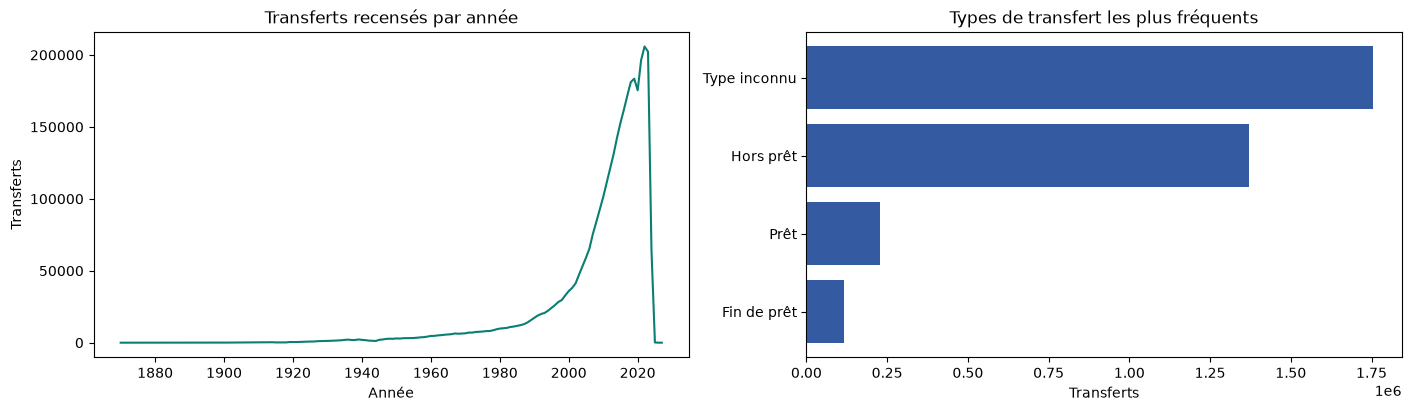

Pic dans le dataset : 2022, avec 205,866 transferts recensés.
Un volume faible peut refléter une année incomplète ou une couverture limitée du dataset.


In [15]:
import matplotlib.pyplot as plt

eda_clean = eda.where(F.col("year").isNotNull())
annual_eda = eda_clean.groupBy("year").count().orderBy("year")
# Traduire uniquement les libellés du tableau et du graphique.
type_labels = {
    "Unknown": "Type inconnu",
    "Not loan": "Hors prêt",
    "Loan": "Prêt",
    "End of loan": "Fin de prêt",
}
types_eda = (
    eda.groupBy("type").count().replace(type_labels, subset=["type"])
    .orderBy(F.desc("count"), "type")
)
annual_eda.show(15)
types_eda.show(15, truncate=False)
year_data = annual_eda.toPandas()
type_data = types_eda.limit(10).toPandas().sort_values("count")
fig, axes = plt.subplots(1, 2, figsize=(14, 4), layout="constrained")
axes[0].plot(year_data["year"], year_data["count"], color="#087f70")
axes[0].set(title="Transferts recensés par année", xlabel="Année", ylabel="Transferts")
axes[1].barh(type_data["type"], type_data["count"], color="#345ba1")
axes[1].set(title="Types de transfert les plus fréquents", xlabel="Transferts")
plt.show()
if not year_data.empty:
    peak = year_data.loc[year_data["count"].idxmax()]
    print(f"Pic dans le dataset : {int(peak['year'])}, avec {int(peak['count']):,} transferts recensés.")
print("Un volume faible peut refléter une année incomplète ou une couverture limitée du dataset.")

+--------+------------------+-------------------------------------------------+-------+
|effectif|moyenne           |quantiles                                        |maximum|
+--------+------------------+-------------------------------------------------+-------+
|58755   |2093145.0584971493|[120000.0, 450000.0, 1750000.0, 5000000.0, 2.5E7]|2.22E8 |
+--------+------------------+-------------------------------------------------+-------+

Moyenne : 2,093,145 | Médiane : 450,000 | IQR : 1,630,000
La moyenne dépasse la médiane. Les montants élevés tirent la moyenne vers le haut.
P90 : 5,000,000 | P99 : 25,000,000 | Maximum : 222,000,000


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


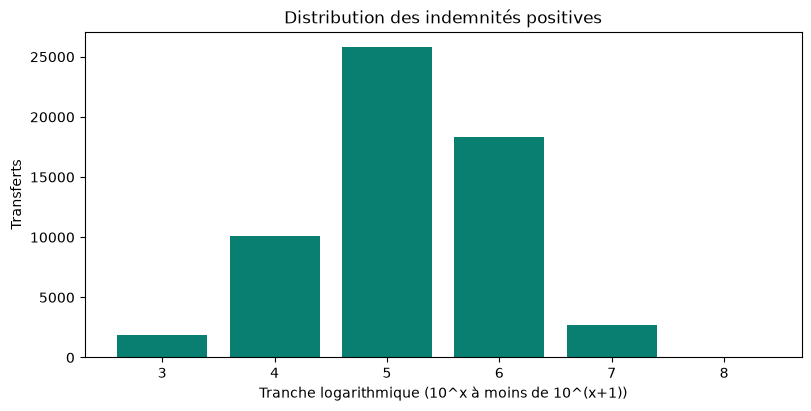

In [16]:
positive = eda.where(finite_fee & (F.col("fee") > 0))
fee_summary = positive.agg(
    F.count("*").alias("effectif"),
    F.avg("fee").alias("moyenne"),
    F.percentile_approx("fee", [0.25, 0.5, 0.75, 0.9, 0.99], 10000).alias("quantiles"),
    F.max("fee").alias("maximum"),
)
fee_summary.show(truncate=False)
stats_eda = fee_summary.first()
if stats_eda["effectif"]:
    p25, median, p75, p90, p99 = stats_eda["quantiles"]
    mean = stats_eda["moyenne"]
    print(f"Moyenne : {mean:,.0f} | Médiane : {median:,.0f} | IQR : {p75 - p25:,.0f}")
    if mean > median:
        print("La moyenne dépasse la médiane. Les montants élevés tirent la moyenne vers le haut.")
    print(f"P90 : {p90:,.0f} | P99 : {p99:,.0f} | Maximum : {stats_eda['maximum']:,.0f}")
    fee_bins = (
        positive.withColumn("log_bin", F.floor(F.log10("fee")))
        .groupBy("log_bin").count().orderBy("log_bin").toPandas()
    )
    fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
    ax.bar(fee_bins["log_bin"], fee_bins["count"], color="#087f70")
    ax.set(title="Distribution des indemnités positives",
           xlabel="Tranche logarithmique (10^x à moins de 10^(x+1))", ylabel="Transferts")
    plt.show()

### 1.3 — Vérifier les rapprochements avant les analyses par championnat
Le taux de rapprochement mesure la part des clés qui trouvent une correspondance sur l’ensemble des transferts. Les référentiels sont réduits à une ligne par clé pour le calcul. La table `club_league` est profilée à sa granularité d’origine avant de choisir comment relier `season` à l’année d’un transfert.

In [17]:
def reference_keys(frame, key):
    return frame.select(F.col("id").try_cast("bigint").alias(key)).where(
        F.col(key).isNotNull()
    ).distinct().withColumn(f"match_{key}", F.lit(1))

matched_eda = eda.join(reference_keys(bronze_dfs["players"], "player_id"), "player_id", "left")
for club_key in ("left_club_id", "joined_club_id"):
    matched_eda = matched_eda.join(reference_keys(bronze_dfs["clubs"], club_key), club_key, "left")

matched_eda.agg(*[
    F.round(100 * F.try_divide(F.count(f"match_{key}"), F.count("*")), 2).alias(f"{key}_pct")
    for key in ("player_id", "left_club_id", "joined_club_id")
]).show(truncate=False)

club_seasons = bronze_dfs["club_league"].select("club_id", "league_id", "season")
club_seasons.groupBy("season").count().orderBy(F.desc("count")).show(15, truncate=False)
club_seasons.groupBy("club_id", "season").agg(
    F.countDistinct("league_id").alias("nb_championnats")
).groupBy("nb_championnats").count().orderBy("nb_championnats").show()

+-------------+----------------+------------------+
|player_id_pct|left_club_id_pct|joined_club_id_pct|
+-------------+----------------+------------------+
|99.43        |77.66           |81.16             |
+-------------+----------------+------------------+

+------+-----+
|season|count|
+------+-----+
|2023  |6848 |
|2022  |6480 |
|2021  |6342 |
|2020  |5953 |
|2019  |5674 |
|2018  |5397 |
|2017  |5129 |
|2016  |4899 |
|2024  |4859 |
|2015  |4580 |
|2014  |4324 |
|2013  |4012 |
|2012  |3742 |
|2011  |3272 |
|2010  |3020 |
+------+-----+
only showing top 15 rows
+---------------+------+
|nb_championnats| count|
+---------------+------+
|              1|121810|
|              2|  2708|
|              3|   235|
|              4|    11|
|              5|     1|
+---------------+------+



### 1.4 — Conclusions de l’EDA
- **Activité.** 2022 est l’année la plus représentée, avec **205 866 transferts recensés**. Cette observation dépend de la couverture du dataset.
- **Indemnités.** Sur **3 469 314** transferts, **58 755** ont un montant strictement positif (environ **1,7 %**). Les autres lignes ont une valeur codée à zéro. Le dataset ne permet pas à lui seul d’interpréter tous ces zéros comme des transferts libres. Parmi les montants positifs, la **médiane** est de **450 000**, la **moyenne** d’environ **2 093 145** et l’**IQR** de **1 630 000**, dans l’unité du dataset. Je retiens la médiane pour décrire une indemnité typique, car les montants les plus élevés tirent la moyenne vers le haut.
- **Jointures.** On retrouve **99,43 %** des joueurs, **77,66 %** des clubs de départ et **81,16 %** des clubs d’arrivée. Ces taux concernent l’identification des clubs, avant leur rattachement à un championnat.
- **Championnats.** La table des affiliations contient **2 955 couples club-saison** associés à plusieurs ligues. En J3, il faudra isoler ces cas et mesurer la couverture des affiliations avant de présenter des flux.

## 2. Harmonisation Inter-Datasets, Nettoyage & Jointure Distribuée (`BroadcastHashJoin` / `SortMergeJoin`)

### Bonnes pratiques de jointure entre plusieurs datasets hétérogènes :
1. **Harmonisation des clés de jointure (*Key Alignment*)** : deux datasets Kaggle d'auteurs différents n'ont presque jamais exactement le même format de clé :
   - *Axe temporel* : ramenez les horodatages à la même granularité et au même fuseau (`F.to_date(...)`, `F.date_trunc("hour", ...)` ou format `yyyy-MM`).
   - *Axe géographique / catégoriel* : normalisez la casse, les espaces et les codes (`F.upper(F.trim(col))`, code ISO pays/région, code postal ou grille `F.round(lat, 2)`).
2. **Prévention des explosions N-à-M** : avant un `LEFT JOIN` de la table principale (`N` lignes) vers un second dataset, assurez-vous que la clé de jointure est **unique côté table secondaire** via une pré-agrégation métier (`groupBy(join_keys).agg(...)`) ou `dropDuplicates(join_keys)` ! Vérifiez systématiquement que le nombre de lignes après `LEFT JOIN` n'explose pas.
3. **Choix de la stratégie physique Spark** :
   - **Table secondaire compacte (< quelques dizaines de Mo)** : forcez **`F.broadcast(df_sec)`** pour obtenir un `BroadcastHashJoin` sans *Shuffle* de la grande table.
   - **Deux grands datasets volumineux** : laissez Spark exécuter un `SortMergeJoin` distribué (optimisé dynamiquement par *Adaptive Query Execution*).

### Exercice 2.1 — Nettoyer, harmoniser vos clés, joindre vos sources et écrire `/lakehouse/silver/<table_silver>`
1. Nettoyez vos tables (`dropDuplicates`, filtrage d'anomalies, typage fort `F.to_timestamp` / `F.to_date` / numériques) et harmonisez la clé de jointure commune.
2. Créez au moins **2 nouvelles colonnes métier dérivées** (dont idéalement un indicateur combinant vos deux sources !) utiles pour les Jours 3 & 4.
3. Réalisez la jointure (avec `F.broadcast(...)` sur une table de dimension/dataset secondaire compact), contrôlez le **taux de rapprochement (*match rate*)** ainsi que l'absence de duplication N-M, et affichez `.explain("simple")`.
4. Écrivez la table enrichie au format **Delta** dans **`/lakehouse/silver/<votre_table>`**.

In [18]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder.appName("J2_Spark_Delta_Silver").getOrCreate()
join_sources = {
    name: spark.read.format("delta").load(f"/lakehouse/bronze/{name}")
    for name in ("transfers", "players", "clubs")
}

# Chemin de notre future table Silver
SILVER_MAIN_PATH = "/lakehouse/silver/football_transfers"

# ÉTAPE 1 : Nettoyer les transferts
df_transfers = join_sources["transfers"]

df_transfers_clean = (
    df_transfers
    .dropDuplicates()
    .withColumn("year", F.col("year").cast("int"))
    .withColumn("transfer_fee", F.col("transfer_fee").cast("double"))
)

count_before_join = df_transfers_clean.count()

print("Transferts après nettoyage :", count_before_join)


# ÉTAPE 2 : Préparer les tables secondaires
df_players = (
    join_sources["players"]
    .select(
        F.col("id").alias("player_key"),
        F.col("name").alias("player_name")
    )
    .dropDuplicates(["player_key"])
)

df_clubs = (
    join_sources["clubs"]
    .select(
        F.col("id").alias("club_key"),
        F.col("club_name")
    )
    .dropDuplicates(["club_key"])
)


# ÉTAPE 3 : Effectuer les jointures
df_silver = (
    df_transfers_clean

    # Relier chaque transfert à son joueur
    .join(
        df_players,
        F.col("player_id") == F.col("player_key"),
        "left"
    )
    .drop("player_key")

    # Relier chaque transfert au club rejoint
    .join(
        F.broadcast(df_clubs),
        F.col("joined_club_id") == F.col("club_key"),
        "left"
    )
    .drop("club_key")

    # Ajouter deux indicateurs métier
    .withColumn(
        "is_paid_transfer",
        F.col("transfer_fee") > 0
    )
    .withColumn(
        "club_identified",
        F.col("club_name").isNotNull()
    )
)

# Vérifier le plan d'exécution Spark
df_silver.explain("simple")


# ÉTAPE 4 : Enregistrer au format Delta Lake
(
    df_silver.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(SILVER_MAIN_PATH)
)

# Vérifier le résultat
silver_count = (
    spark.read
    .format("delta")
    .load(SILVER_MAIN_PATH)
    .count()
)

assert silver_count <= count_before_join, (
    f"Alerte explosion N-M : {silver_count:,} lignes "
    f"après jointure > {count_before_join:,} avant jointure !"
)

print(f"Table Silver écrite dans {SILVER_MAIN_PATH} : {silver_count:,} lignes")

Transferts après nettoyage : 3469314
== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Project [player_id#11926, year#11927, left_club_id#11928, joined_club_id#11929, transfer_fee#11963, transfer_type#11931, _source_file#11932, _ingested_at#11933, _source_dataset#11934, player_name#12063, club_name#12065, (transfer_fee#11963 > 0.0) AS is_paid_transfer#12060, isnotnull(club_name#12065) AS club_identified#12061]
   +- BroadcastHashJoin [joined_club_id#11929], [club_key#12058], LeftOuter, BuildRight, false, false
      :- Project [player_id#11926, year#11927, left_club_id#11928, joined_club_id#11929, transfer_fee#11963, transfer_type#11931, _source_file#11932, _ingested_at#11933, _source_dataset#11934, player_name#12063]
      :  +- BroadcastHashJoin [player_id#11926], [player_key#12055], LeftOuter, BuildRight, false, false
      :     :- HashAggregate(keys=[joined_club_id#11929, _source_dataset#11934, transfer_type#11931, player_id#11926, left_club_id#11928, year#11927, _ingeste

Table Silver écrite dans /lakehouse/silver/football_transfers : 3,469,314 lignes


## 3. Garanties Transactionnelles ACID de Delta Lake

### Exercice 3.1 — Explorer `_delta_log` et vérifier le *Schema Enforcement*
1. Lisez et affichez les premières lignes du fichier JSON de transaction `00000000000000000000.json` situé dans `{SILVER_MAIN_PATH}/_delta_log/`.
2. Tentez d'insérer (`mode("append")`) un petit DataFrame artificiel au schéma incompatible dans `SILVER_MAIN_PATH` et interceptez l'exception levée par Delta Lake.

In [19]:
# 1. Lecture directe du journal transactionnel JSON sur HDFS
spark.read.text(f"{SILVER_MAIN_PATH}/_delta_log/00000000000000000000.json").show(8, truncate=110)

# Delta doit refuser l’ajout de ces colonnes au schéma Silver.
bad_df = spark.createDataFrame([("test_1", "colonne_intruse")], ["fake_id", "intruder_col"])
try:
    bad_df.write.format("delta").mode("append").save(SILVER_MAIN_PATH)
except Exception as e:
    print("Schema Enforcement validé — écriture invalide bloquée :", str(e).splitlines()[0])

+--------------------------------------------------------------------------------------------------------------+
|                                                                                                         value|
+--------------------------------------------------------------------------------------------------------------+
|{"commitInfo":{"timestamp":1794913640913,"operation":"WRITE","operationParameters":{"mode":"Overwrite","par...|
|{"metaData":{"id":"946cbd4f-a4ef-48d7-a032-c4c8ab9c86d9","format":{"provider":"parquet","options":{}},"sche...|
|                                                      {"protocol":{"minReaderVersion":1,"minWriterVersion":2}}|
|{"add":{"path":"part-00000-bca29876-a7d9-4ed2-8fdd-6452d7ed7b18-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00001-3b937ca5-083f-4673-9472-6e9f0f9d0d28-c000.snappy.parquet","partitionValues":{},"...|
|{"add":{"path":"part-00002-1e91b501-4cc2-4f11-a7ed-d353c3f1a5b7-c000.snappy.parquet","partition

### Exercice 3.2 — Upsert (`MERGE INTO`) et Voyage dans le Temps (`VERSION AS OF`)
1. Prélevez un petit lot de lignes existantes dans votre table Silver (ou simulez un lot correctif + 1 nouvelle ligne) et appliquez un **`MERGE INTO`** via `DeltaTable.forPath(spark, SILVER_MAIN_PATH)` (`whenMatchedUpdate` / `whenNotMatchedInsert`).
2. Affichez l'historique des commits avec `DESCRIBE HISTORY` et interrogez la version initiale de la table via `.option("versionAsOf", 0)` pour démontrer l'auditabilité temporelle !

In [20]:
from delta.tables import DeltaTable
from pyspark.sql import functions as F

# 1. Ouvrir la table Silver
target_delta = DeltaTable.forPath(spark, SILVER_MAIN_PATH)

# 2. Lire les données actuelles
df_current = spark.read.format("delta").load(SILVER_MAIN_PATH)

# Conserver la version actuelle avant modification
version_before = target_delta.history(1).select("version").first()[0]

# Je prends un transfert de type inconnu pour suivre la même ligne avant et après le MERGE.
keys = [
    "player_id", "year", "left_club_id",
    "joined_club_id", "transfer_fee", "transfer_type",
    "_source_file", "_ingested_at", "_source_dataset"
]

correction = (
    df_current
    .filter(F.col("transfer_type") == "Unknown")
    .select(*keys)
    .limit(1)
    .withColumn("new_transfer_type", F.lit("Unknown - test MERGE"))
)

assert correction.count() == 1, "Aucun transfert Unknown trouvé."

# 4. Construire la condition de correspondance
condition = " AND ".join(
    f"t.`{c}` <=> s.`{c}`" for c in keys
)

# 5. Appliquer le MERGE INTO
(
    target_delta.alias("t")
    .merge(correction.alias("s"), condition)
    .whenMatchedUpdate(set={
        "transfer_type": "s.new_transfer_type"
    })
    .execute()
)

print("MERGE INTO exécuté avec succès !")

# 6. Afficher l'historique des modifications
history_df = spark.sql(
    f"DESCRIBE HISTORY delta.`{SILVER_MAIN_PATH}`"
)

history_df.select(
    "version", "timestamp", "operation", "operationMetrics"
).show(truncate=80)

# 7. Lire la version avant modification
df_old = (
    spark.read.format("delta")
    .option("versionAsOf", version_before)
    .load(SILVER_MAIN_PATH)
)

# 8. Lire la version actuelle
df_new = spark.read.format("delta").load(SILVER_MAIN_PATH)

print("Avant MERGE :", df_old.filter(
    F.col("transfer_type") == "Unknown - test MERGE"
).count())

print("Après MERGE :", df_new.filter(
    F.col("transfer_type") == "Unknown - test MERGE"
).count())

print("Lignes avant :", df_old.count())
print("Lignes après :", df_new.count())

26/11/18 13:45:06 WARN MapPartitionsRDD: RDD 965 was locally checkpointed, its lineage has been truncated and cannot be recomputed after unpersisting


MERGE INTO exécuté avec succès !
+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|version|              timestamp|operation|                                                                operationMetrics|
+-------+-----------------------+---------+--------------------------------------------------------------------------------+
|      5| 2026-11-18 13:45:05.71|    MERGE|{numTargetRowsCopied -> 277814, numTargetRowsDeleted -> 0, numTargetBytesRemo...|
|      4|2026-11-18 13:44:59.672|    WRITE|{numFiles -> 13, numRemovedFiles -> 13, numRemovedBytes -> 87806422, numOutpu...|
|      3|2026-11-18 13:39:58.073|    MERGE|{numTargetRowsCopied -> 277814, numTargetRowsDeleted -> 0, numTargetBytesRemo...|
|      2|2026-11-18 13:37:02.801|    WRITE|{numFiles -> 13, numRemovedFiles -> 13, numRemovedBytes -> 87922067, numOutpu...|
|      1| 2026-11-17 14:20:23.94|    MERGE|{numTargetRowsCopied -> 277814, numTargetRowsDele

Avant MERGE : 0
Après MERGE : 1
Lignes avant : 3469314
Lignes après : 3469314
